# Aula 15 — Laboratório: Modelos de Classificação

**Especialização em Ciência de Dados · Análise e Ciência de Dados · IFRN**
Unidade 4 — Aprendizado de Máquina Aplicado (segunda aula)

### Caso da aula — o tumor é benigno ou maligno?
Usaremos um dataset **real e público**, baixado do **Kaggle**: o *Breast Cancer Wisconsin (Diagnostic)*. São **569 exames** de punção aspirativa por agulha fina (PAAF) de nódulos de mama. De cada exame, uma imagem digitalizada das células foi medida: raio, textura, perímetro, área, concavidade etc. dos núcleos celulares. Cada exame tem o **diagnóstico confirmado**: `M` = maligno ou `B` = benigno.

Pergunta: **a partir das medidas da imagem, um modelo consegue classificar o tumor?** É um problema de **classificação binária** em que as classes se separam bem — por isso conseguimos **ver claramente** como cada modelo decide e onde cada um erra.

Vamos treinar e comparar **quatro classificadores** do scikit-learn, com o fluxo da Aula 14:

`dados → X e y → treino/teste → baseline → Regressão Logística · Árvore de Decisão · Random Forest · KNN → validação cruzada → matriz de confusão → curva ROC → escolha`

> **Fonte:** Kaggle — UCI Machine Learning, *Breast Cancer Wisconsin (Diagnostic) Data Set* (https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data), arquivo `data.csv`, aqui salvo como `dados/breast_cancer_wisconsin.csv`. Dados originais: W. H. Wolberg, W. N. Street e O. L. Mangasarian, Universidade de Wisconsin (UCI Machine Learning Repository). Os registros são anônimos (só medidas da imagem e diagnóstico).
>
> ⚕️ Este é um exercício de aprendizado de máquina, **não** uma ferramenta de diagnóstico.

### Roteiro (1h30)

| Tempo | Parte | O que você vai ver |
|---|---|---|
| 0–10 min | 0. Dados e pergunta | download no Kaggle, limpeza mínima, alvo, proporção das classes |
| 10–20 min | 1. Treino/teste e baseline | `train_test_split` estratificado, `DummyClassifier` |
| 20–50 min | 2. Os quatro modelos | `LogisticRegression`, `DecisionTreeClassifier`, `RandomForestClassifier`, `KNeighborsClassifier` |
| 50–60 min | 3. Como cada modelo "desenha" a fronteira | fronteiras de decisão em 2 variáveis |
| 60–70 min | 4. Comparação justa | `StratifiedKFold` + `cross_validate` com os quatro modelos |
| 70–85 min | 5. Teste final | matrizes de confusão, métricas, curvas ROC, limiar |
| 85–90 min | Fechamento | quando usar cada modelo |

### Dicionário — `dados/breast_cancer_wisconsin.csv`
| Coluna | Descrição |
|---|---|
| `id` | número do exame (não é informação útil para o modelo) |
| **`diagnosis`** | **alvo**: `M` = maligno, `B` = benigno |
| 10 medidas do núcleo celular | `radius` (raio), `texture` (textura: desvio-padrão dos tons de cinza), `perimeter` (perímetro), `area` (área), `smoothness` (suavidade do contorno), `compactness` (compacidade), `concavity` (concavidade), `concave points` (nº de pontos côncavos do contorno), `symmetry` (simetria), `fractal_dimension` (dimensão fractal) |
| sufixos | `_mean` = média dos núcleos da imagem · `_se` = erro-padrão · `_worst` = média dos 3 piores (maiores) valores |
| `Unnamed: 32` | coluna vazia que vem no arquivo do Kaggle (será removida) |

São 10 medidas × 3 sufixos = **30 atributos numéricos**, sem valores faltantes.

## Parte 0 — Dados e pergunta

**Como baixar do Kaggle** (o pacote já traz uma cópia; faça isso para praticar):
1. Entre em https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data (é preciso uma conta gratuita).
2. Clique em **Download**, descompacte e copie `data.csv` para a pasta `dados/`.
3. Troque o caminho na célula abaixo para `"dados/data.csv"` — o conteúdo é o mesmo.

Alternativa por código (requer `pip install kagglehub` e login no Kaggle):
```python
import kagglehub
pasta = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
CAMINHO = f"{pasta}/data.csv"
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["axes.titleweight"] = "bold"
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
SEMENTE = 42  # fixar a semente torna os resultados reproduzíveis
CORES = {"Regressão logística": "#0173b2", "Árvore de decisão": "#de8f05",
         "Random forest": "#029e73", "KNN": "#cc78bc"}

CAMINHO = "dados/breast_cancer_wisconsin.csv"   # = data.csv do Kaggle
bruto = pd.read_csv(CAMINHO)
print(bruto.shape)
bruto.iloc[:5, :8]

(569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280


In [2]:
# Limpeza mínima: o id não ajuda a prever e "Unnamed: 32" é uma coluna vazia do arquivo do Kaggle
print("valores na coluna 'Unnamed: 32':", bruto["Unnamed: 32"].notna().sum())
df = bruto.drop(columns=["id", "Unnamed: 32"])
print("faltantes no restante:", df.isna().sum().sum(), "| linhas duplicadas:", df.duplicated().sum())

# Alvo numérico: 1 = maligno (a classe que queremos encontrar), 0 = benigno
df["maligno"] = (df["diagnosis"] == "M").astype(int)
print("\nProporção das classes:")
print(df["diagnosis"].value_counts(), "\n")
print(df["maligno"].value_counts(normalize=True).round(3))

valores na coluna 'Unnamed: 32': 0
faltantes no restante: 0 | linhas duplicadas: 0

Proporção das classes:
diagnosis
B    357
M    212
Name: count, dtype: int64 

maligno
0    0.627
1    0.373
Name: proportion, dtype: float64


**Leitura:** 357 benignos e 212 malignos — **37,3% malignos**. As classes são um pouco desbalanceadas, e o erro mais grave é deixar passar um tumor **maligno** (falso negativo). Por isso a classe positiva (1) é **maligno**, e o **recall** dessa classe vai importar muito.

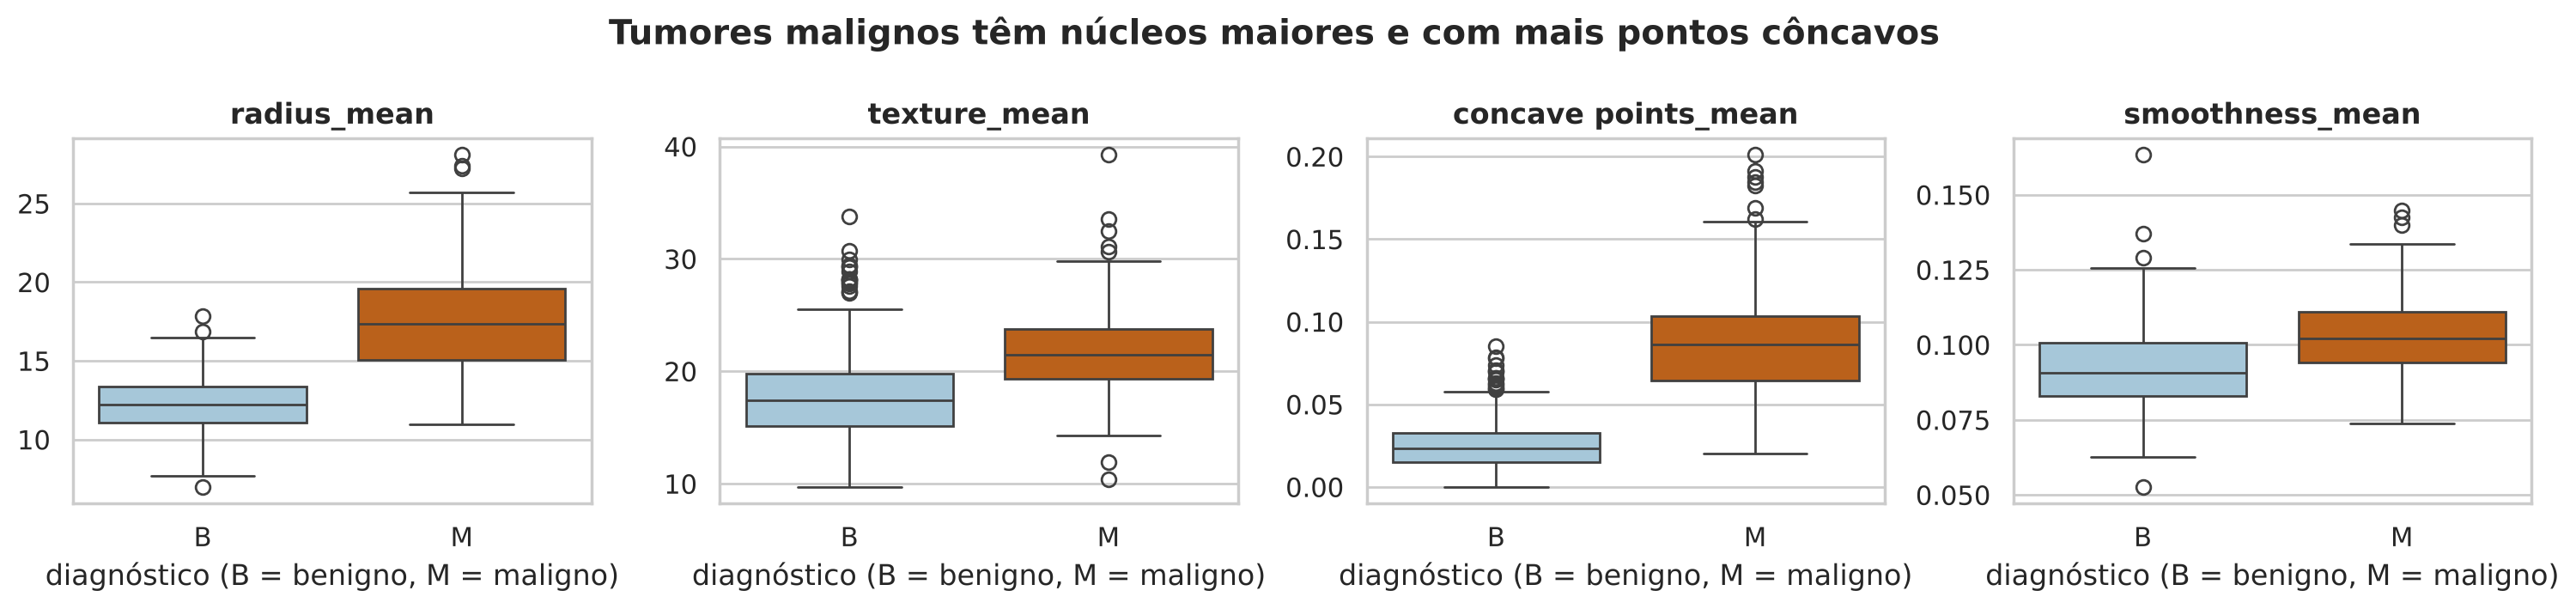

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col in zip(axes, ["radius_mean", "texture_mean", "concave points_mean", "smoothness_mean"]):
    sns.boxplot(data=df, x="diagnosis", y=col, hue="diagnosis", order=["B", "M"], hue_order=["B", "M"],
                palette={"B": "#9ecae1", "M": "#d55e00"}, legend=False, ax=ax)
    ax.set(title=col, xlabel="diagnóstico (B = benigno, M = maligno)", ylabel="")
fig.suptitle("Tumores malignos têm núcleos maiores e com mais pontos côncavos", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "01_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

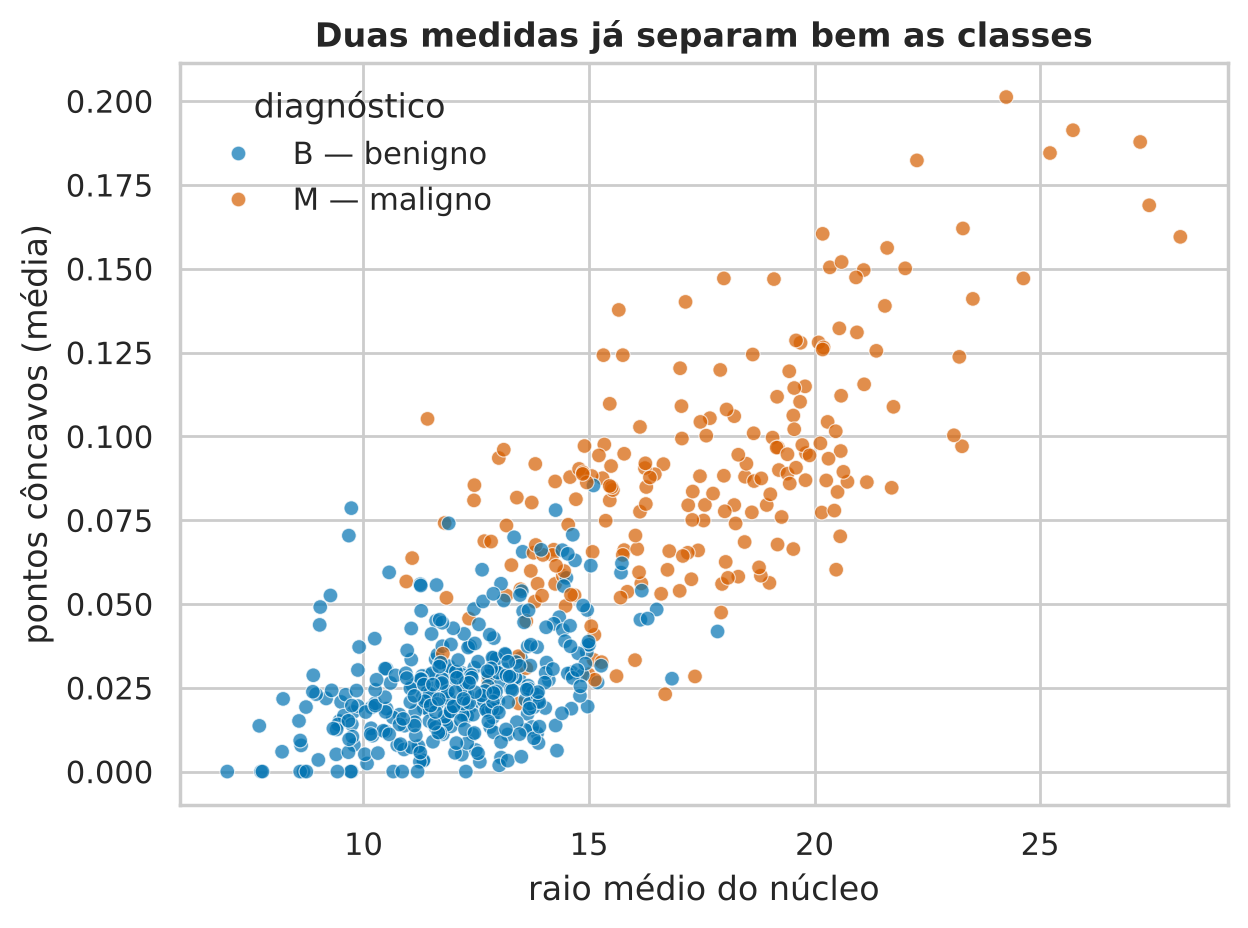

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
rotulo = df["diagnosis"].map({"B": "B — benigno", "M": "M — maligno"})
sns.scatterplot(data=df, x="radius_mean", y="concave points_mean", hue=rotulo, hue_order=["B — benigno", "M — maligno"],
                palette={"B — benigno": "#0173b2", "M — maligno": "#d55e00"}, alpha=.7, s=28, ax=ax)
ax.set(title="Duas medidas já separam bem as classes", xlabel="raio médio do núcleo",
       ylabel="pontos côncavos (média)")
ax.legend(title="diagnóstico", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "02_dispersao.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura:** com só duas medidas os grupos já aparecem quase separados; a sobreposição fica numa faixa estreita (raio entre ~13 e ~17). É nessa faixa que os modelos vão divergir — e é isso que vamos comparar.

## Parte 1 — Treino/teste e baseline

Mesmo fluxo da Aula 14: separamos 25% para **teste** com `stratify=y` e guardamos esse conjunto até o fim. O **baseline** (`DummyClassifier`) chuta sempre a classe mais comum.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

X = df.drop(columns=["diagnosis", "maligno"])   # 30 atributos numéricos
y = df["maligno"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print(f"treino: {X_treino.shape} | teste: {X_teste.shape}")
print(f"% malignos — treino: {y_treino.mean():.3f} | teste: {y_teste.mean():.3f}")

dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
pred_dummy = dummy.predict(X_teste)
print(f"\nBaseline — acurácia: {accuracy_score(y_teste, pred_dummy):.3f} | "
      f"recall (malignos encontrados): {recall_score(y_teste, pred_dummy):.3f}")

treino: (426, 30) | teste: (143, 30)
% malignos — treino: 0.373 | teste: 0.371

Baseline — acurácia: 0.629 | recall (malignos encontrados): 0.000


**Leitura:** o baseline acerta **62,9%** chutando sempre "benigno" e **não encontra nenhum** dos 53 tumores malignos do teste. Qualquer modelo útil precisa superar isso com folga — e com recall alto.

## Parte 2 — Os quatro modelos

Todos seguem a mesma API (`fit`, `predict`, `predict_proba`), mas **aprendem de jeitos muito diferentes**:

| Modelo | Ideia | Precisa padronizar? | Hiperparâmetros principais |
|---|---|---|---|
| **Regressão logística** | soma ponderada dos atributos → probabilidade (curva sigmoide); fronteira **linear** | sim (recomendado) | `C` (regularização) |
| **Árvore de decisão** | sequência de perguntas "atributo ≤ valor?" | não | `max_depth`, `min_samples_leaf` |
| **Random forest** | muitas árvores diferentes votando | não | `n_estimators`, `max_features`, `min_samples_leaf` |
| **KNN** | olha os *k* vizinhos mais próximos e vota | **sim, obrigatório** | `n_neighbors` (*k*) |

### 2.1 Regressão logística
Calcula uma pontuação $z = b_0 + b_1x_1 + \dots + b_px_p$ e a transforma em probabilidade com a **sigmoide** $p = 1/(1+e^{-z})$. Se $p \ge 0{,}5$, prevê "maligno". Com atributos padronizados, os coeficientes são comparáveis entre si.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistica = Pipeline([("padronizar", StandardScaler()),
                      ("classificador", LogisticRegression(max_iter=1000))])
logistica.fit(X_treino, y_treino)
print(f"acurácia — treino: {logistica.score(X_treino, y_treino):.3f} | teste: {logistica.score(X_teste, y_teste):.3f}")

# Probabilidade de malignidade para 5 exames do teste
amostra = X_teste.head(5)
pd.DataFrame({"P(maligno)": logistica.predict_proba(amostra)[:, 1].round(3),
              "previsto": logistica.predict(amostra), "real": y_teste.head(5).values}, index=amostra.index)

acurácia — treino: 0.988 | teste: 0.965


,P(maligno),previsto,real
12,0.999,1,1
506,0.004,0,0
321,1.000,1,1
71,0.000,0,0
375,0.035,0,0


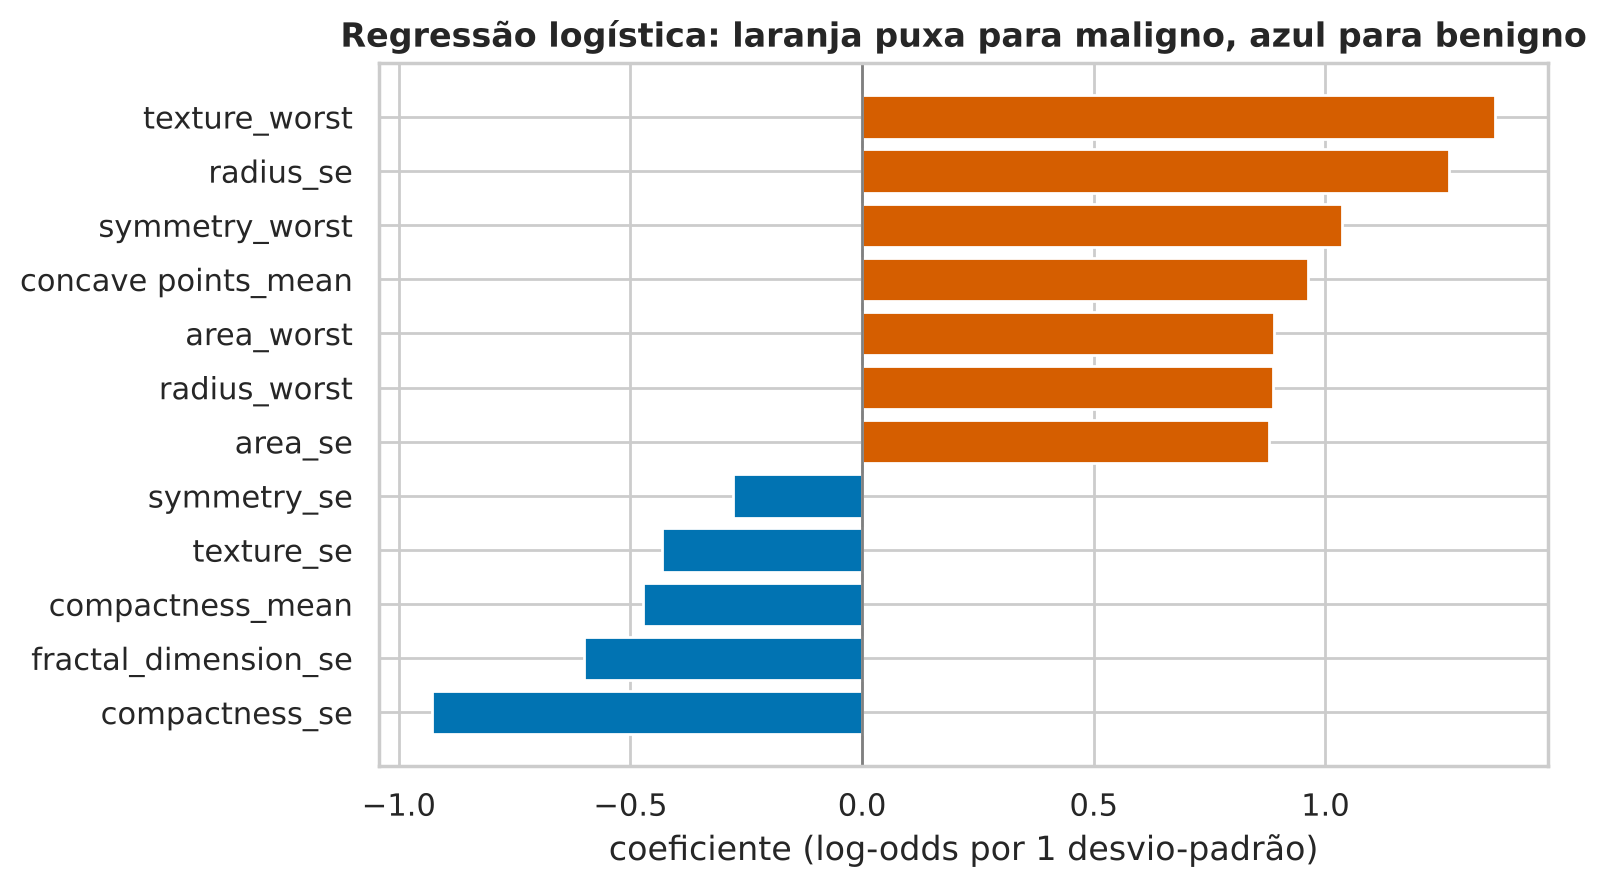

In [7]:
coefs = pd.Series(logistica.named_steps["classificador"].coef_[0], index=X.columns).sort_values()
top = pd.concat([coefs.head(5), coefs.tail(7)])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=["#0173b2" if v < 0 else "#d55e00" for v in top.values])
ax.axvline(0, color="gray", lw=1)
ax.set(title="Regressão logística: laranja puxa para maligno, azul para benigno",
       xlabel="coeficiente (log-odds por 1 desvio-padrão)")
fig.tight_layout(); fig.savefig(FIG / "03_coeficientes_logistica.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura:** textura (`texture_worst`), variação do raio (`radius_se`), simetria, pontos côncavos e tamanho (`area_worst`, `radius_worst`) puxam para **maligno**. Alguns atributos aparecem com sinal "estranho" (ex.: `compactness_se` negativo) porque as 30 medidas são **muito correlacionadas** entre si (raio, perímetro e área medem quase a mesma coisa): o modelo divide o peso entre elas. Coeficiente é associação dentro do modelo, não causa.

### 2.2 Árvore de decisão
A árvore faz perguntas do tipo "`perimeter_worst` ≤ 112,8?" e escolhe, a cada nó, a pergunta que mais **purifica** os grupos (índice de **Gini**). Sem limite, ela cresce até acertar **todo** o treino — e decora ruído (**sobreajuste**, *overfitting*).

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas = []
for prof in [1, 2, 3, 4, 5, 6, 8, None]:
    arv = DecisionTreeClassifier(max_depth=prof, random_state=SEMENTE).fit(X_treino, y_treino)
    linhas.append({"max_depth": "sem limite" if prof is None else prof,
                   "folhas": arv.get_n_leaves(),
                   "acurácia no treino": arv.score(X_treino, y_treino),
                   "acurácia na validação cruzada": cross_val_score(arv, X_treino, y_treino, cv=cv).mean()})
tab_prof = pd.DataFrame(linhas).round(3)
tab_prof

,max_depth,folhas,acurácia no treino,acurácia na validação cruzada
0,1,2,0.930,0.915
1,2,4,0.955,0.929
2,3,7,0.967,0.930
3,4,11,0.979,0.927
4,5,14,0.988,0.941
5,6,18,0.995,0.922
6,8,21,1.000,0.922
7,sem limite,21,1.000,0.916


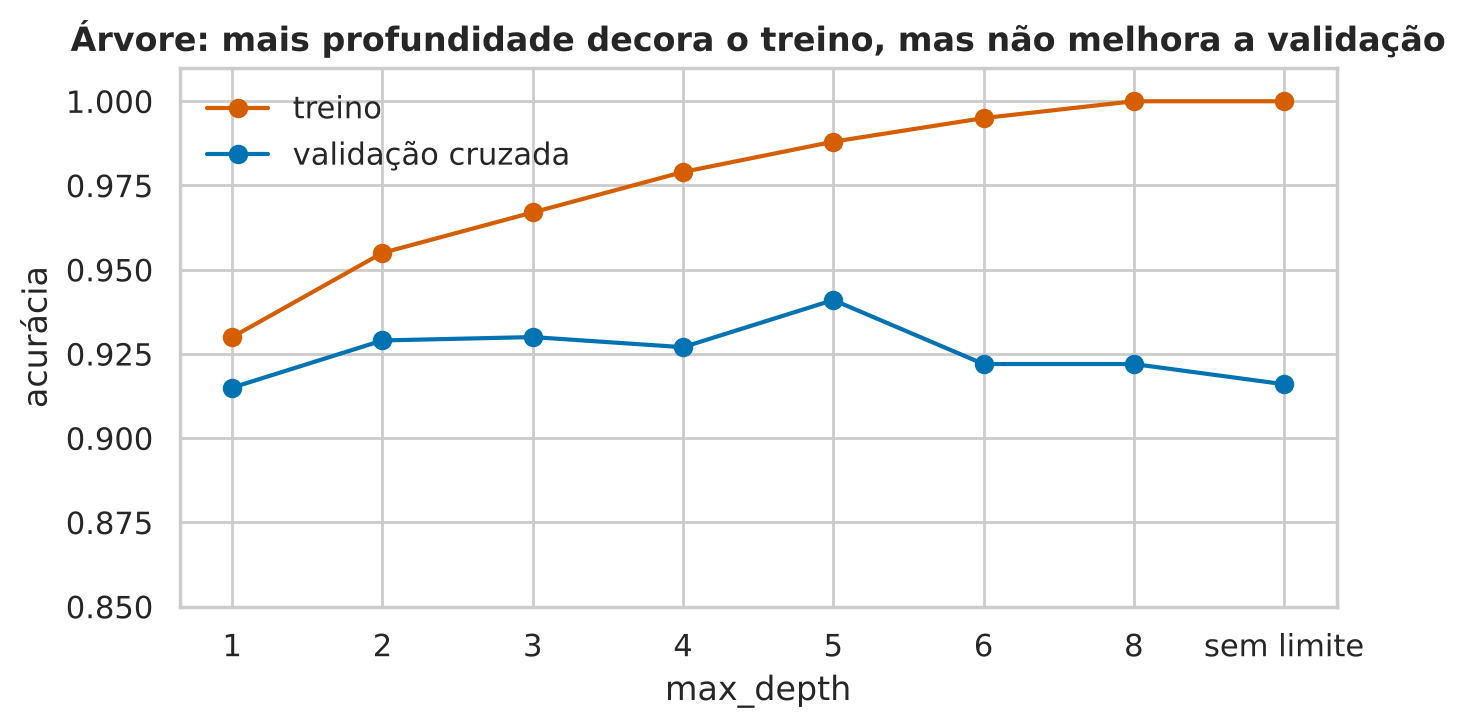

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
xs = tab_prof["max_depth"].astype(str)
ax.plot(xs, tab_prof["acurácia no treino"], marker="o", color="#d55e00", label="treino")
ax.plot(xs, tab_prof["acurácia na validação cruzada"], marker="o", color="#0173b2", label="validação cruzada")
ax.set(title="Árvore: mais profundidade decora o treino, mas não melhora a validação",
       xlabel="max_depth", ylabel="acurácia", ylim=(0.85, 1.01))
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "04_arvore_profundidade.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura:** sem limite, a árvore chega a **100% no treino** com 21 folhas, mas na validação cruzada fica em torno de **92%** — o ganho no treino é decoreba. A partir de profundidade 2–5 a validação já não melhora. Vamos usar uma **árvore podada**: `max_depth=4` e `min_samples_leaf=5` (cada folha com pelo menos 5 exames).

Para **ver** como a árvore decide, desenhamos uma versão com 3 níveis:

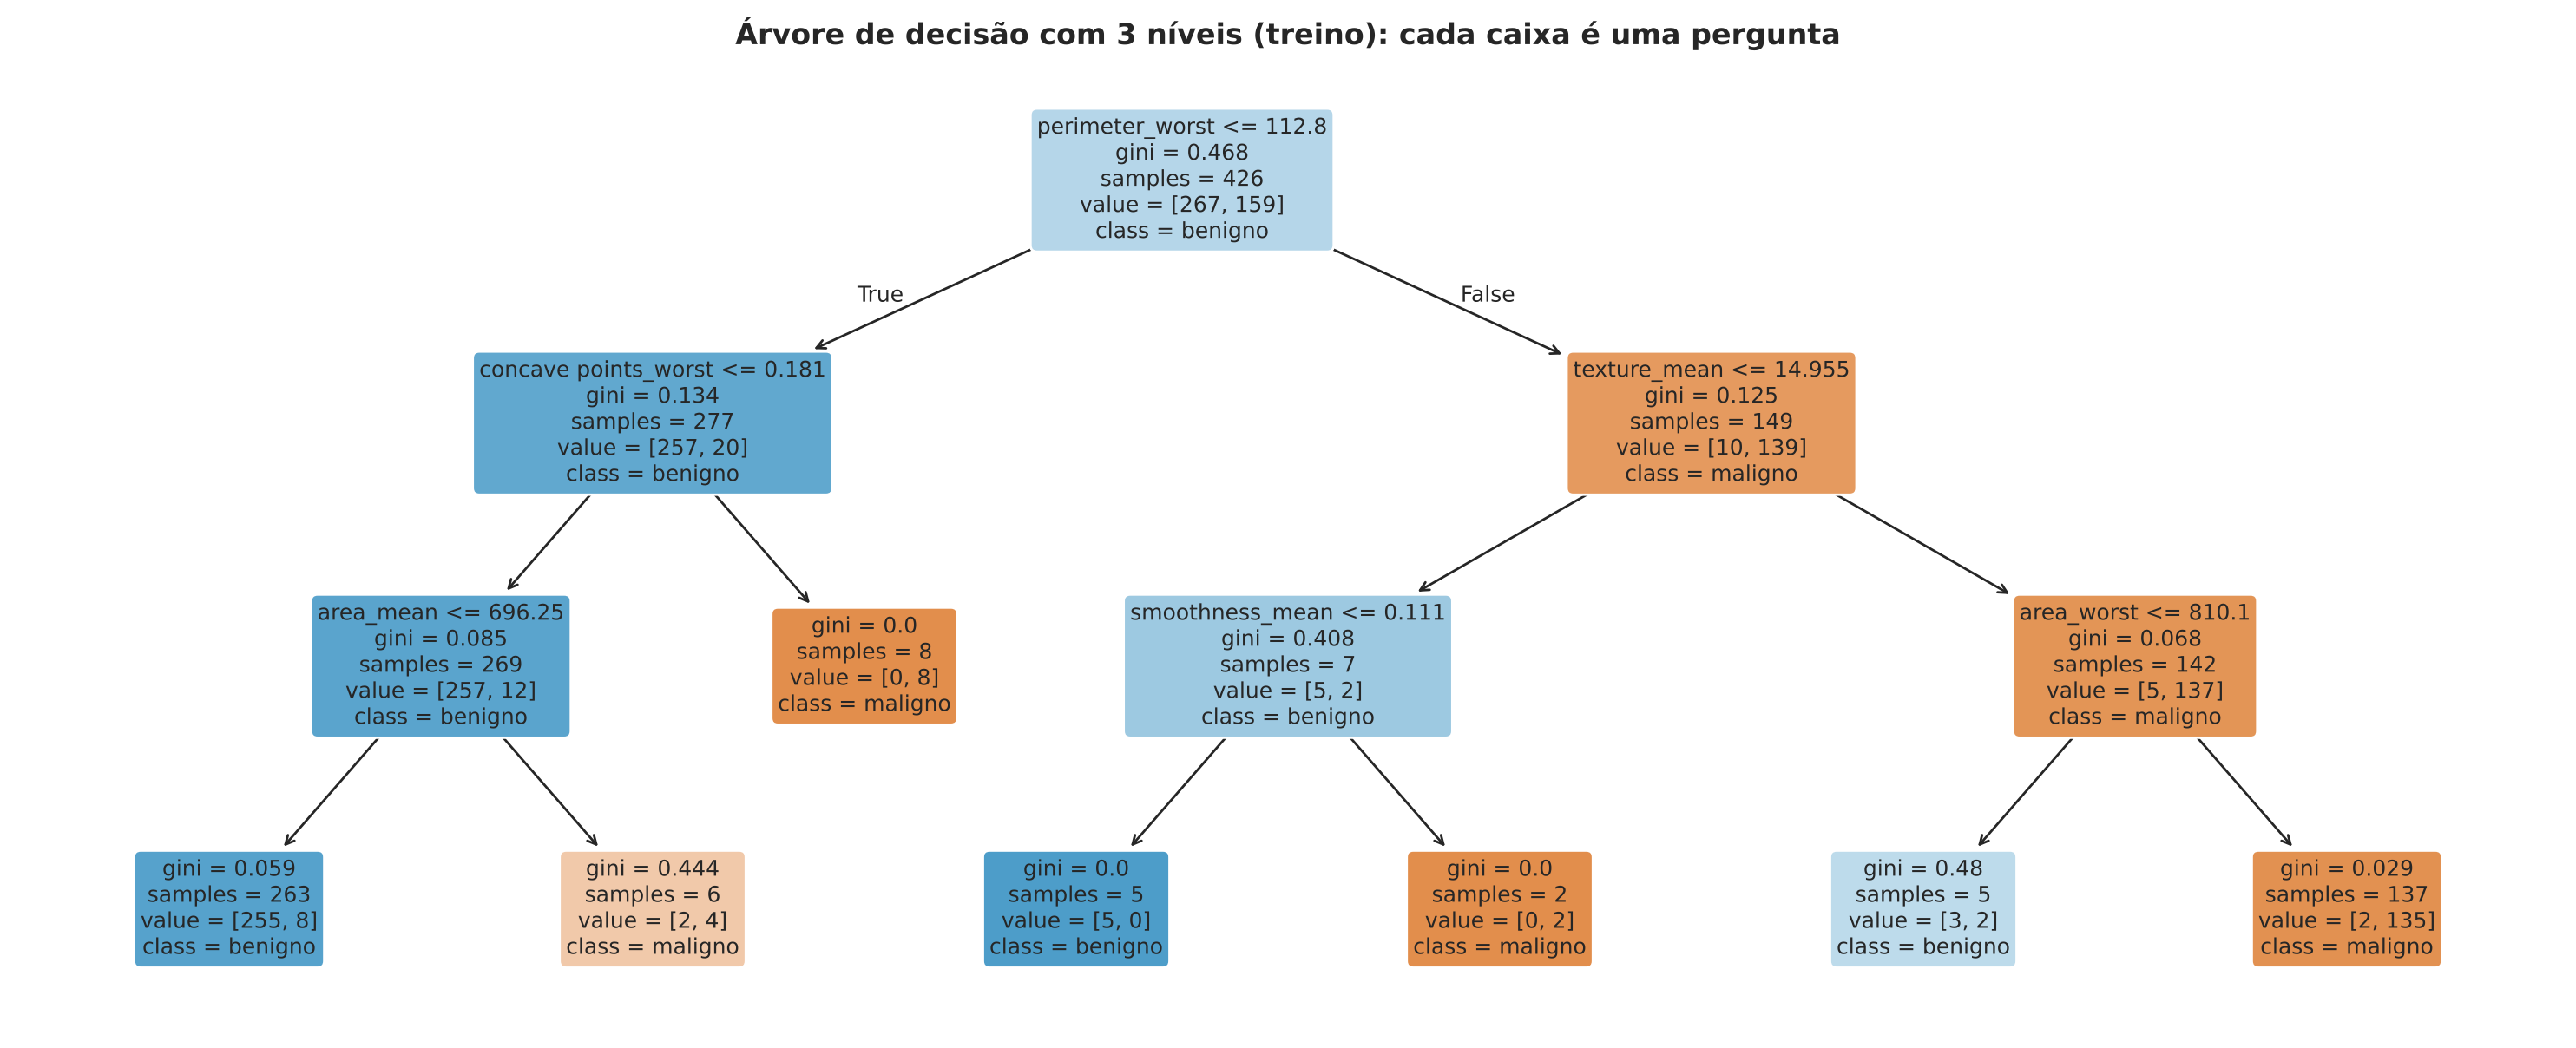

In [10]:
arvore_vis = DecisionTreeClassifier(max_depth=3, random_state=SEMENTE).fit(X_treino, y_treino)
fig, ax = plt.subplots(figsize=(15, 6.2))
caixas = plot_tree(arvore_vis, feature_names=X.columns, class_names=["benigno", "maligno"], filled=True,
                   rounded=True, impurity=True, proportion=False, fontsize=9, ax=ax)
# recolore: azul = benigno, laranja = maligno (mais forte = grupo mais puro)
from matplotlib.colors import to_rgb
azul, laranja, branco = np.array(to_rgb("#0173b2")), np.array(to_rgb("#d55e00")), np.ones(3)
caixas = [c for c in caixas if c.get_bbox_patch() is not None]   # ignora os rótulos True/False
for caixa, valores in zip(caixas, arvore_vis.tree_.value[:, 0, :]):
    p_mal = valores[1] / valores.sum()
    base, forca = (laranja, 2 * p_mal - 1) if p_mal >= 0.5 else (azul, 1 - 2 * p_mal)
    caixa.get_bbox_patch().set_facecolor(branco + (base - branco) * (0.15 + 0.55 * forca))
ax.set_title("Árvore de decisão com 3 níveis (treino): cada caixa é uma pergunta", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "05_arvore.png", dpi=150, bbox_inches="tight"); plt.show()

**Como ler:** comece no topo. Exames com `perimeter_worst` ≤ 112,8 e poucos pontos côncavos (`concave points_worst` ≤ 0,18) e área média pequena vão para a folha **benigno**. Cada caixa mostra o índice de Gini (0 = grupo puro), quantos exames chegaram ali (`samples`), quantos de cada classe (`value` = [benignos, malignos]) e a classe prevista; azul = benigno, laranja = maligno (cor mais forte = grupo mais puro). **A árvore é o modelo mais fácil de explicar** — mas pequenas mudanças nos dados mudam muito as perguntas (instabilidade).

In [11]:
arvore = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=SEMENTE).fit(X_treino, y_treino)
print(f"Árvore podada — acurácia treino: {arvore.score(X_treino, y_treino):.3f} | teste: {arvore.score(X_teste, y_teste):.3f}")

Árvore podada — acurácia treino: 0.962 | teste: 0.888


### 2.3 Random forest
Uma **floresta** de árvores diferentes: cada árvore é treinada numa **amostra com reposição** do treino (*bootstrap*) e, em cada nó, só pode escolher entre um **subconjunto aleatório de atributos**. A previsão é a **votação** (média das probabilidades). Árvores diferentes erram em lugares diferentes, e os erros se compensam: menos variância, mais estabilidade.

Bônus: os exames que ficaram fora do *bootstrap* de cada árvore servem como validação gratuita — o **score OOB** (*out-of-bag*).

Random forest — acurácia treino: 1.000 | OOB: 0.955 | teste: 0.958


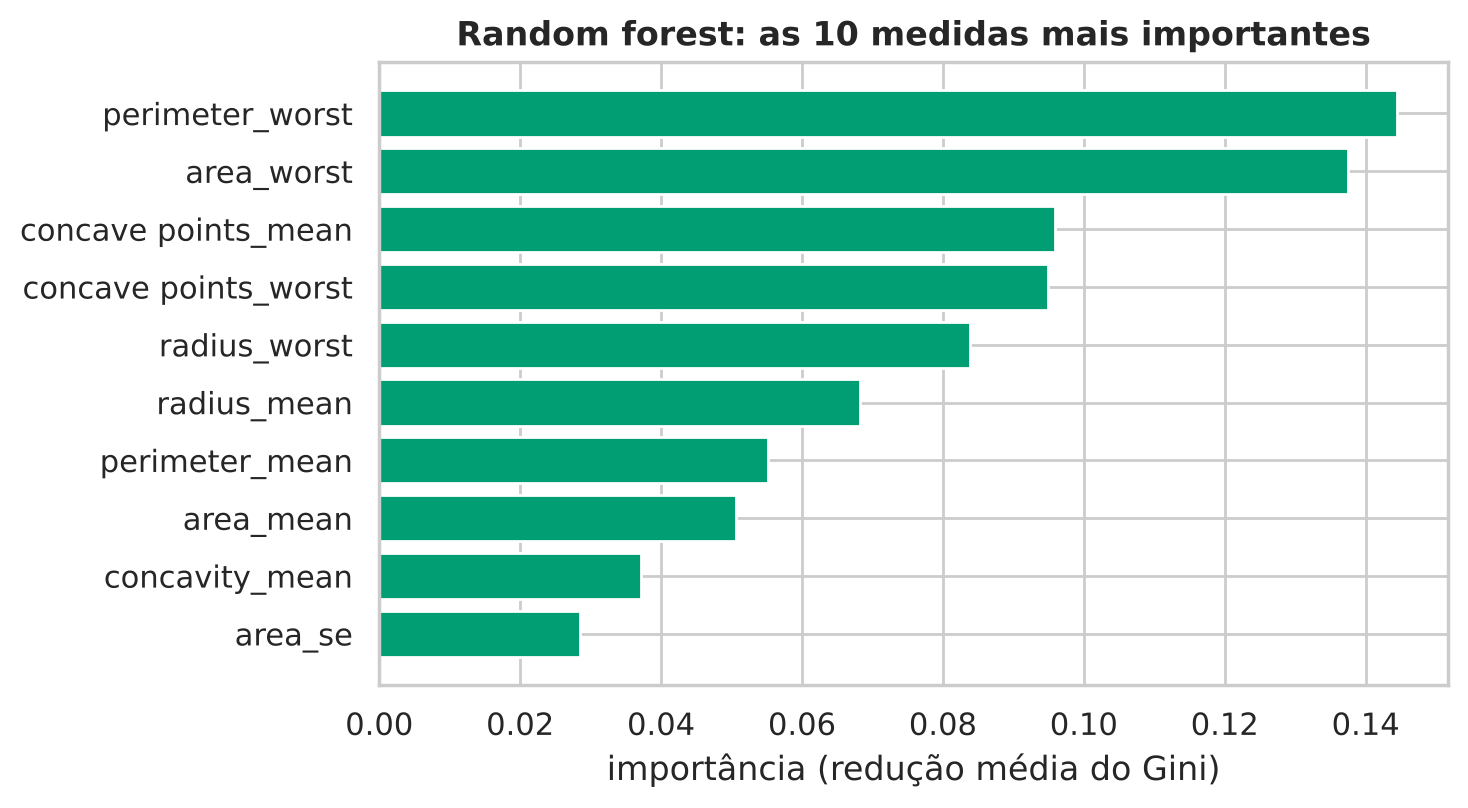

In [12]:
from sklearn.ensemble import RandomForestClassifier

floresta = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEMENTE, n_jobs=-1)
floresta.fit(X_treino, y_treino)
print(f"Random forest — acurácia treino: {floresta.score(X_treino, y_treino):.3f} | "
      f"OOB: {floresta.oob_score_:.3f} | teste: {floresta.score(X_teste, y_teste):.3f}")

imp = pd.Series(floresta.feature_importances_, index=X.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(imp.index, imp.values, color="#029e73")
ax.set(title="Random forest: as 10 medidas mais importantes", xlabel="importância (redução média do Gini)")
fig.tight_layout(); fig.savefig(FIG / "06_importancia_floresta.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura:** a floresta também acerta 100% do treino (cada árvore é profunda), mas o **OOB de 95,5%** mostra o desempenho realista. As medidas mais importantes são de **tamanho** (`perimeter_worst`, `area_worst`, `radius_worst`) e de **pontos côncavos** — as mesmas que vimos separar as classes na Parte 0. Importância diz *quanto* o modelo usa a variável, não em que direção.

### 2.4 KNN — *k* vizinhos mais próximos
Para classificar um exame novo, o KNN mede a **distância** até todos os exames do treino, pega os *k* mais próximos e faz uma votação. Não há "treino" de verdade: o modelo **guarda** os dados.

Por usar distância, a **escala** importa: `area_mean` vai de 143 a 2.501, `smoothness_mean` de 0,05 a 0,16. Sem padronizar, a área domina a distância e as outras 29 medidas quase não contam.

In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn_sem_escala = KNeighborsClassifier(n_neighbors=5)
knn = Pipeline([("padronizar", StandardScaler()), ("classificador", KNeighborsClassifier(n_neighbors=5))])
for nome, modelo in [("KNN sem padronizar", knn_sem_escala), ("KNN com StandardScaler", knn)]:
    acc_cv = cross_val_score(modelo, X_treino, y_treino, cv=cv).mean()
    rec_cv = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="recall").mean()
    print(f"{nome:24s} validação cruzada — acurácia: {acc_cv:.3f} | recall: {rec_cv:.3f}")

KNN sem padronizar       validação cruzada — acurácia: 0.932 | recall: 0.874
KNN com StandardScaler   validação cruzada — acurácia: 0.958 | recall: 0.899


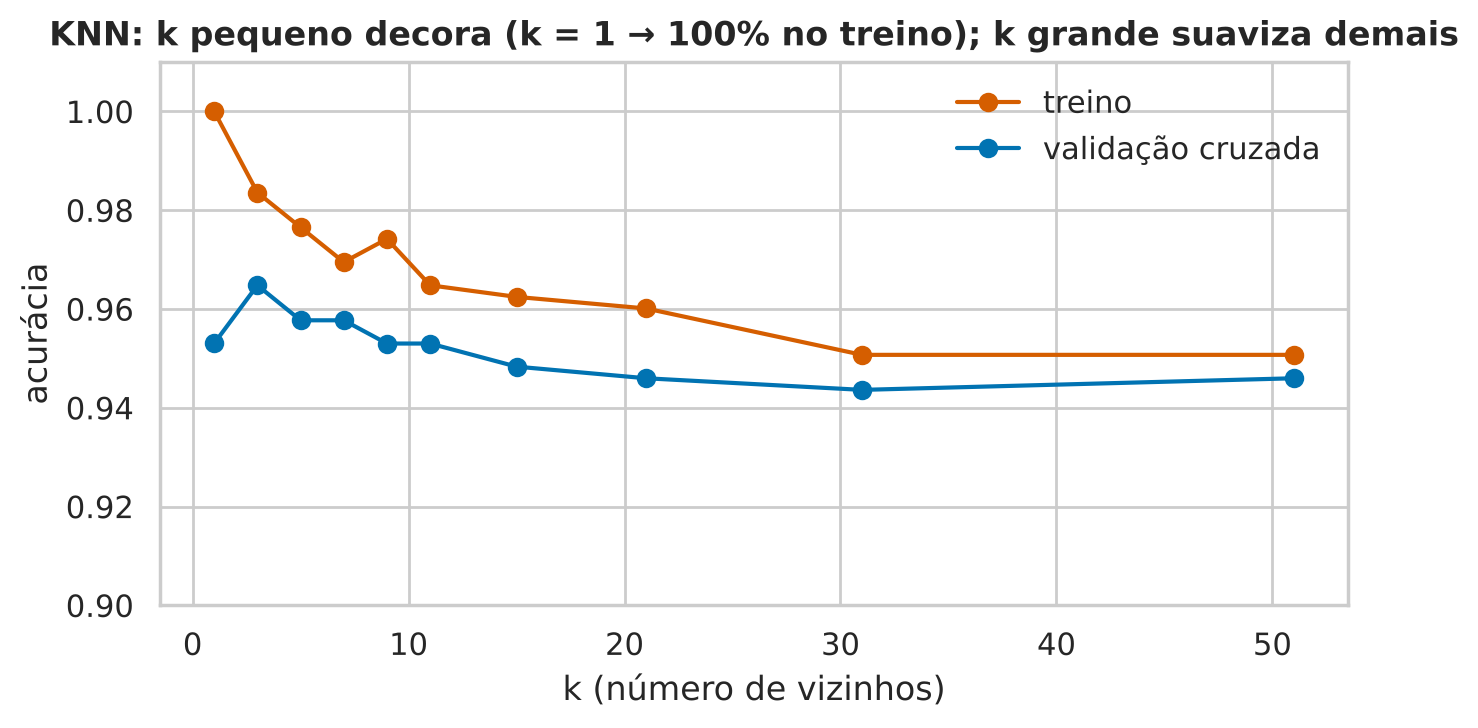

k,1,3,5,7,9,11,15,21,31,51
treino,1.000,0.984,0.977,0.969,0.974,0.965,0.962,0.960,0.951,0.951
validação cruzada,0.953,0.965,0.958,0.958,0.953,0.953,0.948,0.946,0.944,0.946


In [14]:
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]
linhas = []
for k in ks:
    m = Pipeline([("padronizar", StandardScaler()), ("classificador", KNeighborsClassifier(n_neighbors=k))])
    m.fit(X_treino, y_treino)
    linhas.append({"k": k, "treino": m.score(X_treino, y_treino),
                   "validação cruzada": cross_val_score(m, X_treino, y_treino, cv=cv).mean()})
tab_k = pd.DataFrame(linhas)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tab_k["k"], tab_k["treino"], marker="o", color="#d55e00", label="treino")
ax.plot(tab_k["k"], tab_k["validação cruzada"], marker="o", color="#0173b2", label="validação cruzada")
ax.set(title="KNN: k pequeno decora (k = 1 → 100% no treino); k grande suaviza demais",
       xlabel="k (número de vizinhos)", ylabel="acurácia", ylim=(0.9, 1.01))
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "07_knn_k.png", dpi=150, bbox_inches="tight"); plt.show()
tab_k.round(3).set_index("k").T

**Leitura:** padronizar sobe a acurácia do KNN de **93,2% para 95,8%** e o recall de **87,4% para 89,9%** — mesma técnica, só mudou a escala. Na curva, **k = 1** acerta 100% do treino (cada exame é vizinho de si mesmo) e k muito grande perde detalhe; entre 3 e 11 o desempenho é parecido. Ficamos com o padrão **k = 5**.

## Parte 3 — Como cada modelo "desenha" a fronteira

Para **enxergar** a diferença entre os modelos, treinamos cada um com apenas **duas** medidas (`radius_mean` e `concave points_mean`) e pintamos a região que ele classifica como maligno (laranja) ou benigno (azul). Os pontos são os exames de **teste**.

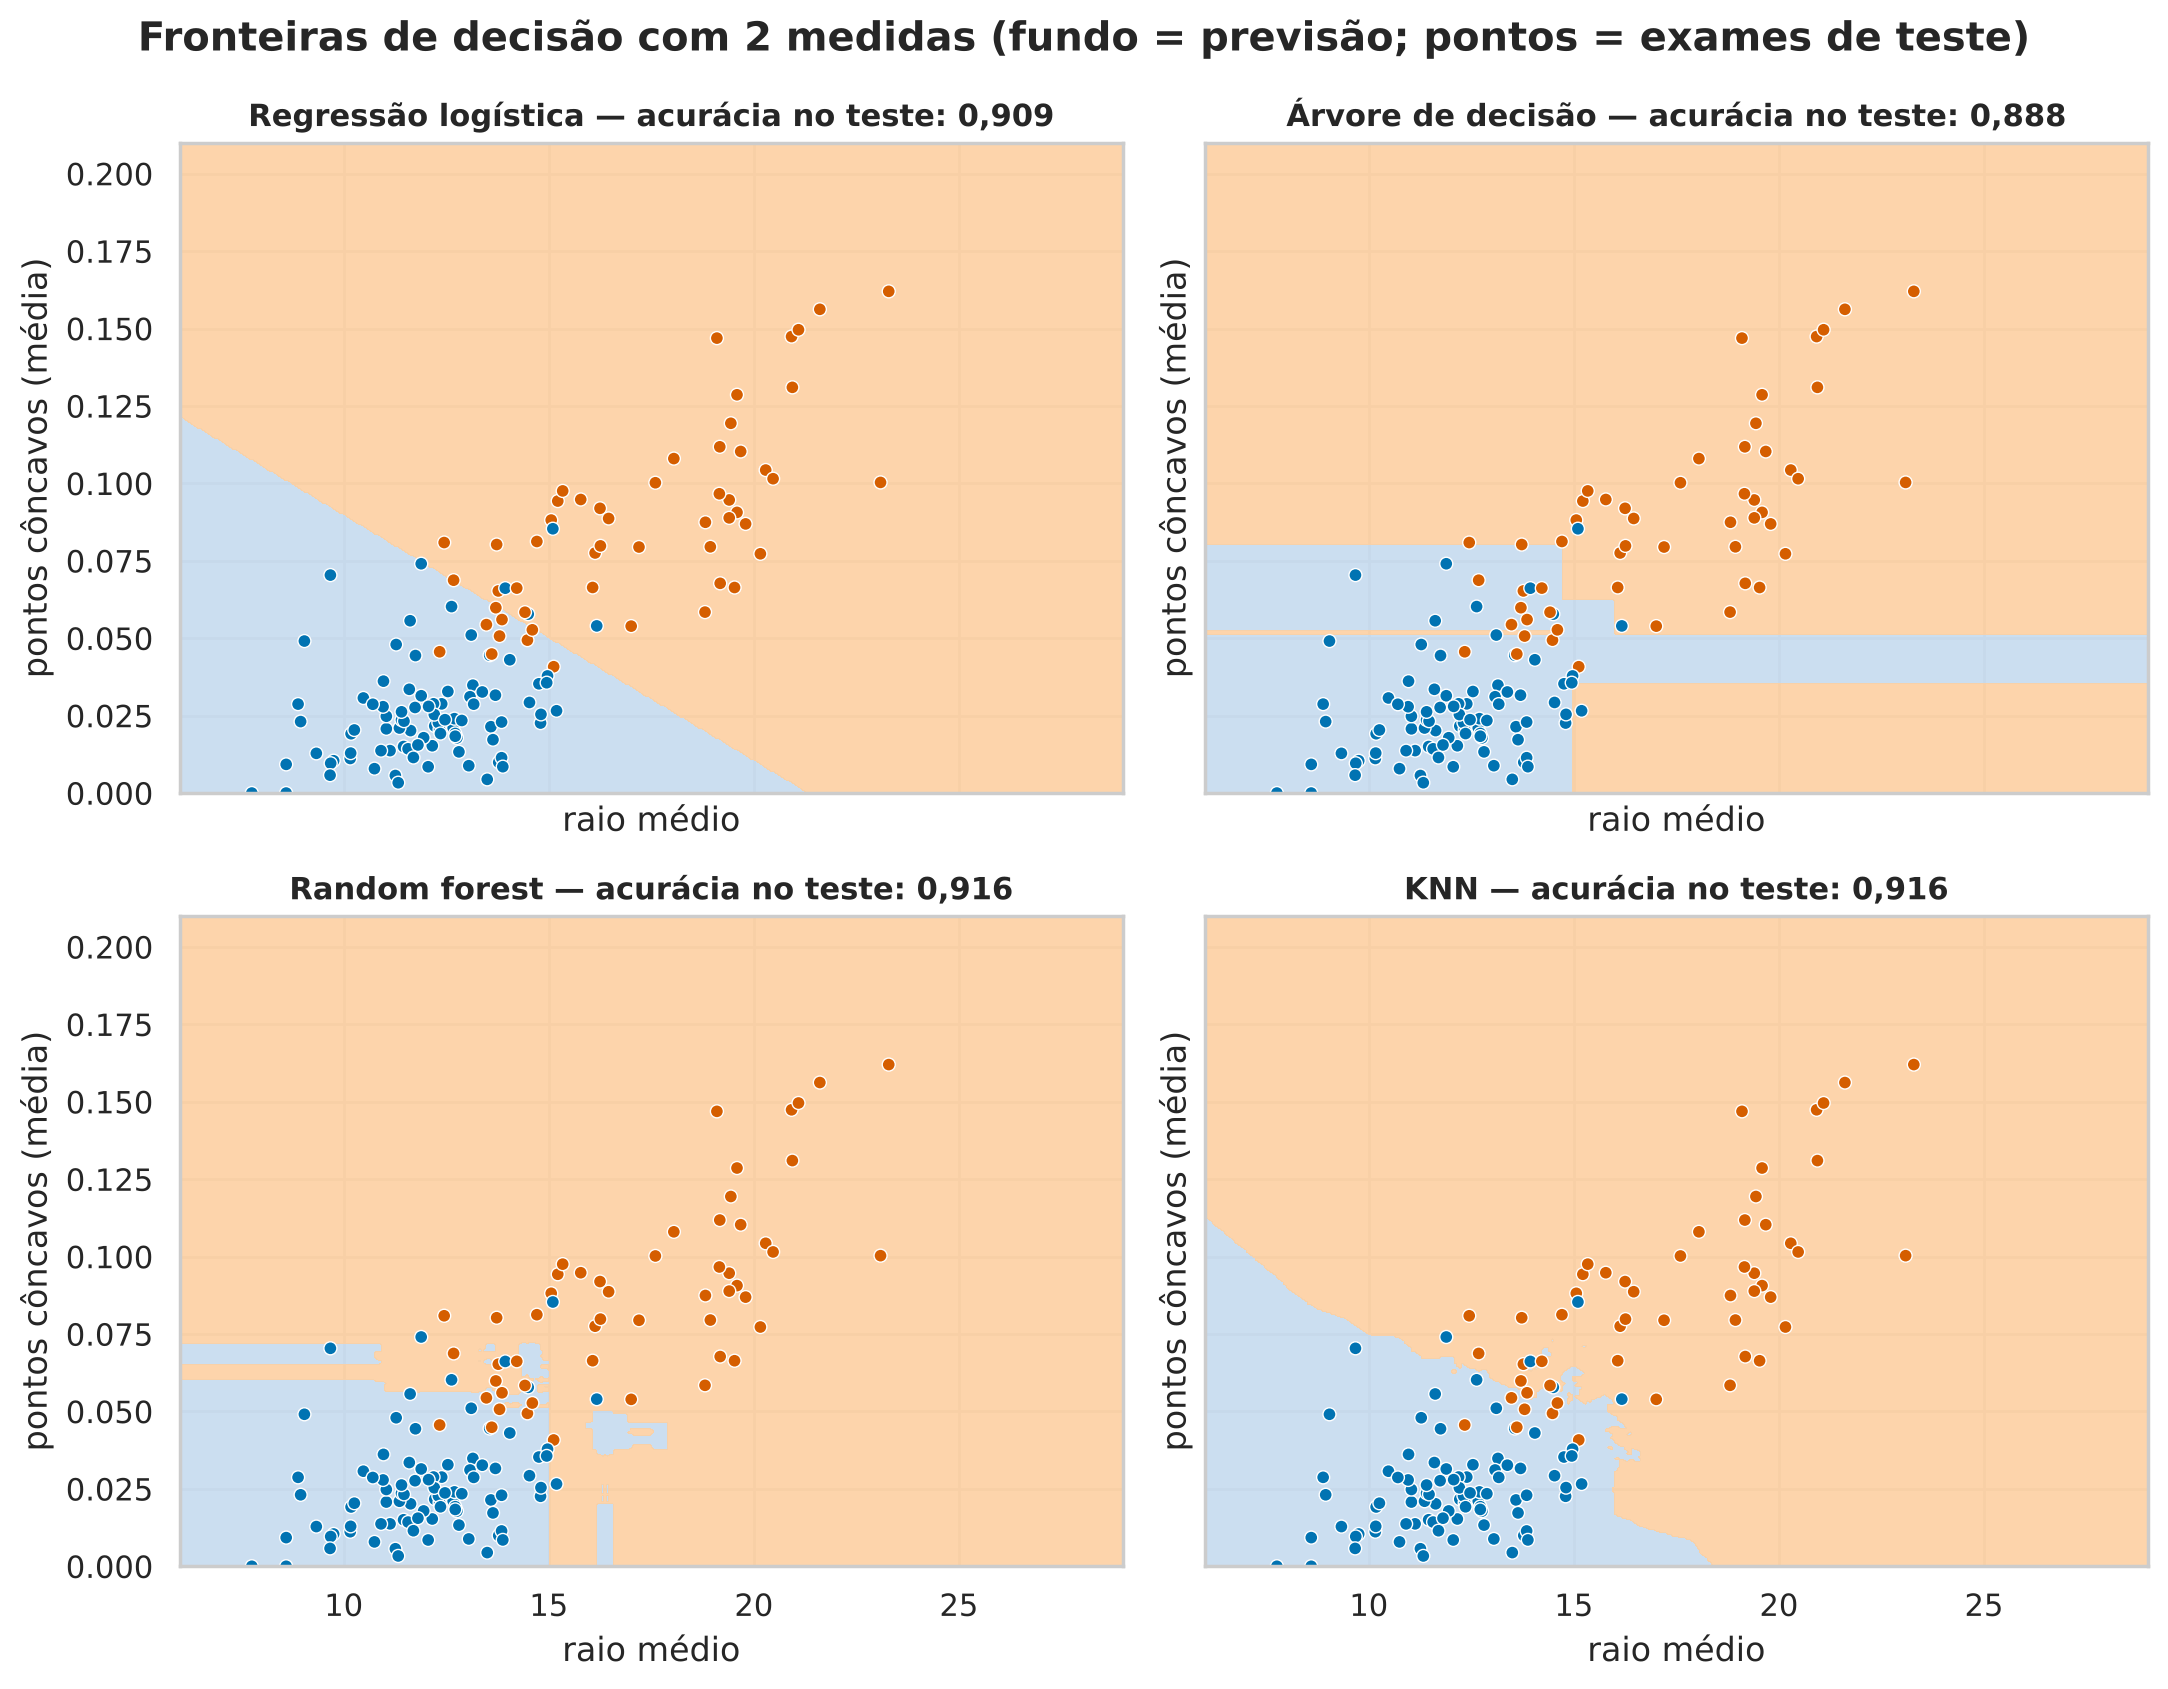

In [15]:
from matplotlib.colors import ListedColormap

par = ["radius_mean", "concave points_mean"]
modelos_2d = {
    "Regressão logística": Pipeline([("padronizar", StandardScaler()), ("classificador", LogisticRegression(max_iter=1000))]),
    "Árvore de decisão": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=SEMENTE),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEMENTE, n_jobs=-1),
    "KNN": Pipeline([("padronizar", StandardScaler()), ("classificador", KNeighborsClassifier(n_neighbors=15))]),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 8.6), sharex=True, sharey=True)
fundo = ListedColormap(["#c6dbef", "#fdd0a2"])
for ax, (nome, m) in zip(axes.ravel(), modelos_2d.items()):
    m.fit(X_treino[par], y_treino)
    # grade de pontos cobrindo o gráfico: o modelo prevê a classe de cada ponto da grade
    gx, gy = np.meshgrid(np.linspace(6, 29, 400), np.linspace(0, 0.21, 400))
    grade = pd.DataFrame({par[0]: gx.ravel(), par[1]: gy.ravel()})
    zz = m.predict(grade).reshape(gx.shape)
    ax.contourf(gx, gy, zz, levels=[-0.5, 0.5, 1.5], cmap=fundo, alpha=.9)
    ax.set(xlabel="raio médio", ylabel="pontos côncavos (média)")
    ax.scatter(X_teste[par[0]], X_teste[par[1]], c=y_teste.map({0: "#0173b2", 1: "#d55e00"}),
               s=22, edgecolor="white", linewidth=.5)
    acc = m.score(X_teste[par], y_teste)
    ax.set_title(f"{nome} — acurácia no teste: {acc:.3f}".replace(".", ","), fontsize=11)
fig.suptitle("Fronteiras de decisão com 2 medidas (fundo = previsão; pontos = exames de teste)", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "08_fronteiras.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura — cada modelo tem uma "assinatura" visual:**
* **Regressão logística:** uma **reta**. Simples e estável; não captura curvas.
* **Árvore de decisão:** **degraus** (retângulos), porque cada pergunta corta um atributo por vez.
* **Random forest:** também retangular, mas com bordas mais **recortadas**, com pequenas "ilhas" onde os pontos se misturam — é a votação de 300 árvores diferentes.
* **KNN:** fronteira **irregular e curva**, que segue a nuvem de pontos local.

Com só 2 medidas as acurácias ficam entre 89% e 92%; com as 30 medidas, todos melhoram. Na faixa de sobreposição (raio entre 13 e 17) é onde cada modelo erra de um jeito diferente.

## Parte 4 — Comparação justa com validação cruzada

Para escolher o modelo **sem tocar no teste**, rodamos a validação cruzada estratificada (5 *folds*) no treino, com as mesmas divisões para todos. Medimos acurácia, **recall** (malignos encontrados), F1 e ROC-AUC.

In [16]:
from sklearn.model_selection import cross_validate

modelos = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": logistica,
    "Árvore de decisão": arvore,
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
    "KNN": knn,
}
resultados, folds = [], []
for nome, m in modelos.items():
    r = cross_validate(m, X_treino, y_treino, cv=cv,
                       scoring=["accuracy", "recall", "f1", "roc_auc"], return_train_score=True)
    resultados.append({"modelo": nome,
                       "acurácia (treino)": r["train_accuracy"].mean(),
                       **{f"{n} (média)": r[f"test_{k}"].mean() for k, n in
                          [("accuracy", "acurácia"), ("recall", "recall"), ("f1", "F1"), ("roc_auc", "ROC-AUC")]},
                       "ROC-AUC (dp)": r["test_roc_auc"].std(),
                       "tempo de ajuste (s)": r["fit_time"].mean()})
    folds += [{"modelo": nome, "fold": i + 1, "ROC-AUC": v, "recall": rc}
              for i, (v, rc) in enumerate(zip(r["test_roc_auc"], r["test_recall"]))]
tab_cv = pd.DataFrame(resultados).set_index("modelo")
tab_cv.round(3)

,acurácia (treino),acurácia (média),recall (média),F1 (média),ROC-AUC (média),ROC-AUC (dp),tempo de ajuste (s)
modelo,,,,,,,
Baseline (Dummy),0.627,0.627,0.000,0.000,0.500,0.000,0.001
Regressão logística,0.989,0.972,0.944,0.961,0.991,0.009,0.004
Árvore de decisão,0.969,0.934,0.912,0.913,0.948,0.022,0.003
Random forest,1.000,0.962,0.937,0.949,0.988,0.009,0.276
KNN,0.972,0.958,0.899,0.941,0.983,0.007,0.003


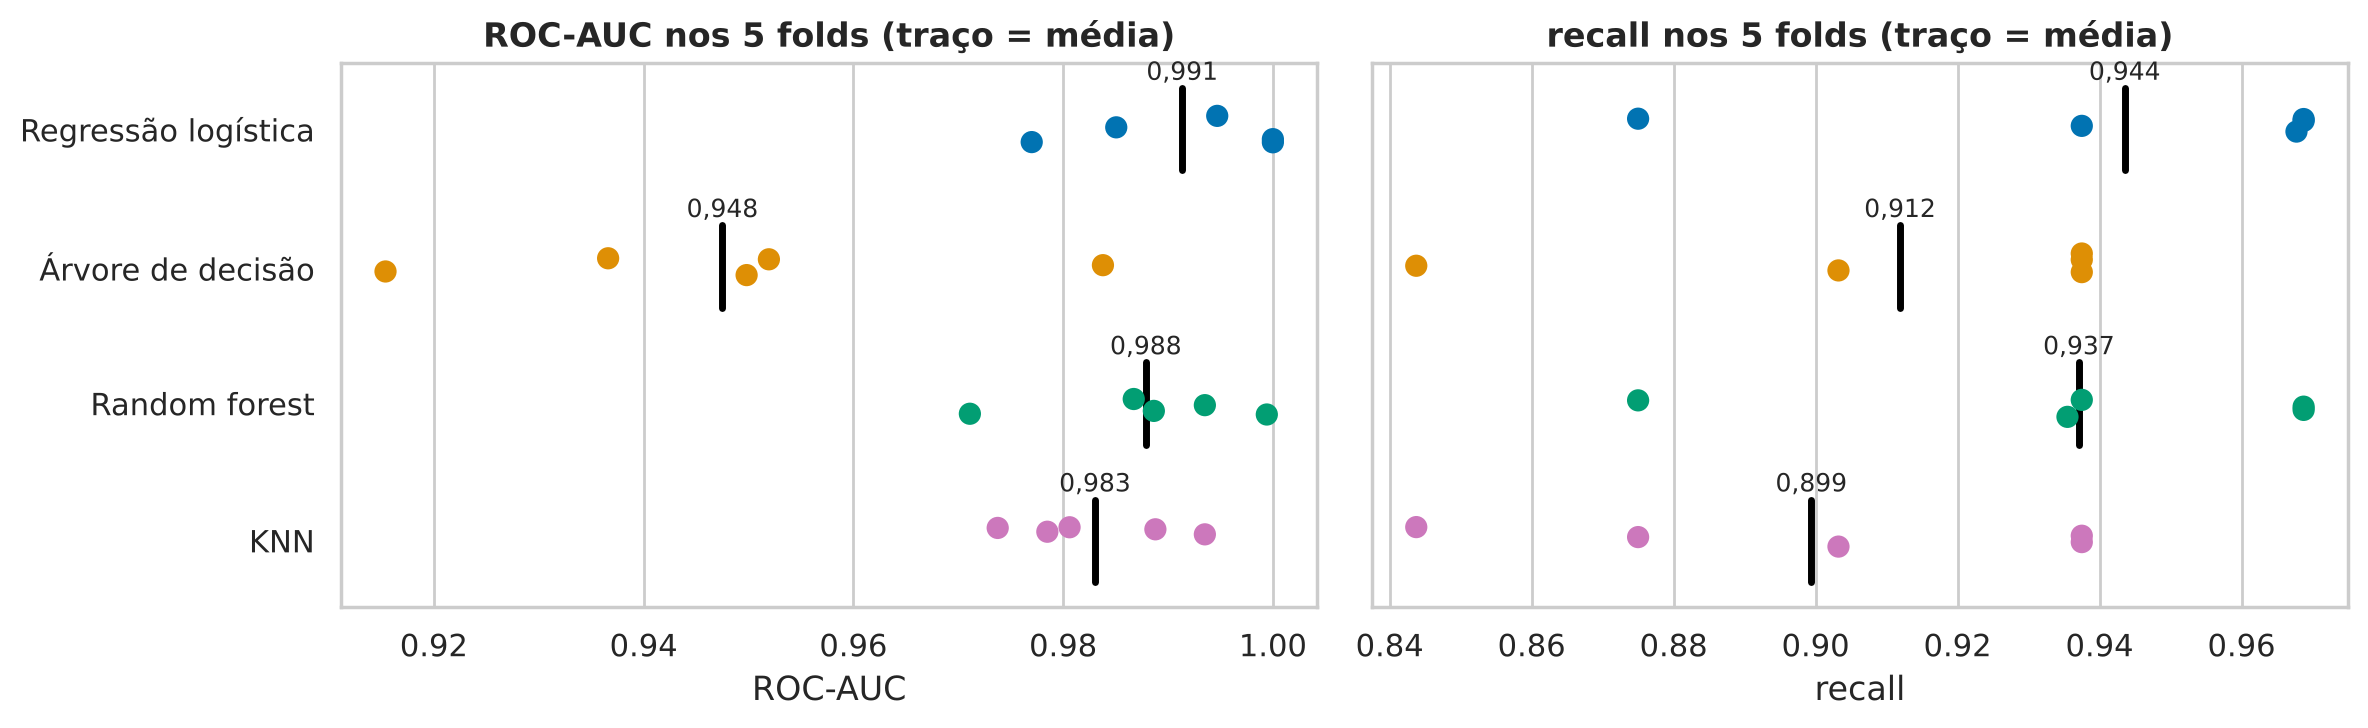

In [17]:
dfolds = pd.DataFrame(folds).query("modelo != 'Baseline (Dummy)'")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, met in zip(axes, ["ROC-AUC", "recall"]):
    sns.stripplot(data=dfolds, x=met, y="modelo", hue="modelo", palette=CORES, size=8, legend=False, ax=ax)
    for i, nome in enumerate(CORES):
        mu = dfolds.query("modelo == @nome")[met].mean()
        ax.plot([mu, mu], [i - 0.3, i + 0.3], color="black", lw=2.5)
        ax.text(mu, i - 0.36, f"{mu:.3f}".replace(".", ","), ha="center", fontsize=9)
    ax.set(title=f"{met} nos 5 folds (traço = média)", xlabel=met, ylabel="")
fig.tight_layout(); fig.savefig(FIG / "09_validacao_cruzada.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura:**
* **Regressão logística** lidera em todas as métricas (acurácia ≈ 97%, ROC-AUC ≈ 0,99) com pouca variação entre os folds — quando a fronteira entre as classes é quase linear, o modelo mais simples vence.
* **Random forest** fica muito perto (ROC-AUC ≈ 0,99), sem precisar padronizar.
* **KNN** (padronizado) vem em seguida, com acurácia ≈ 96%.
* **Árvore de decisão** isolada tem a pior acurácia, F1 e ROC-AUC (0,948) e é a que mais varia entre os folds (veja os pontos laranja espalhados) — o preço da instabilidade. Seu recall médio (0,912) até parece bom, mas oscila de 0,84 a 0,94 conforme o fold.
* Todos ficam muito acima do baseline (ROC-AUC 0,5; recall 0).

A coluna "acurácia (treino)" confirma o diagnóstico: floresta com 100% no treino, mas ≈ 96% na validação. **O que vale é a validação.**

## Parte 5 — Teste final: matriz de confusão, métricas e curva ROC

Agora, e só agora, avaliamos os quatro modelos **uma única vez** no conjunto de teste (143 exames: 90 benignos e 53 malignos).

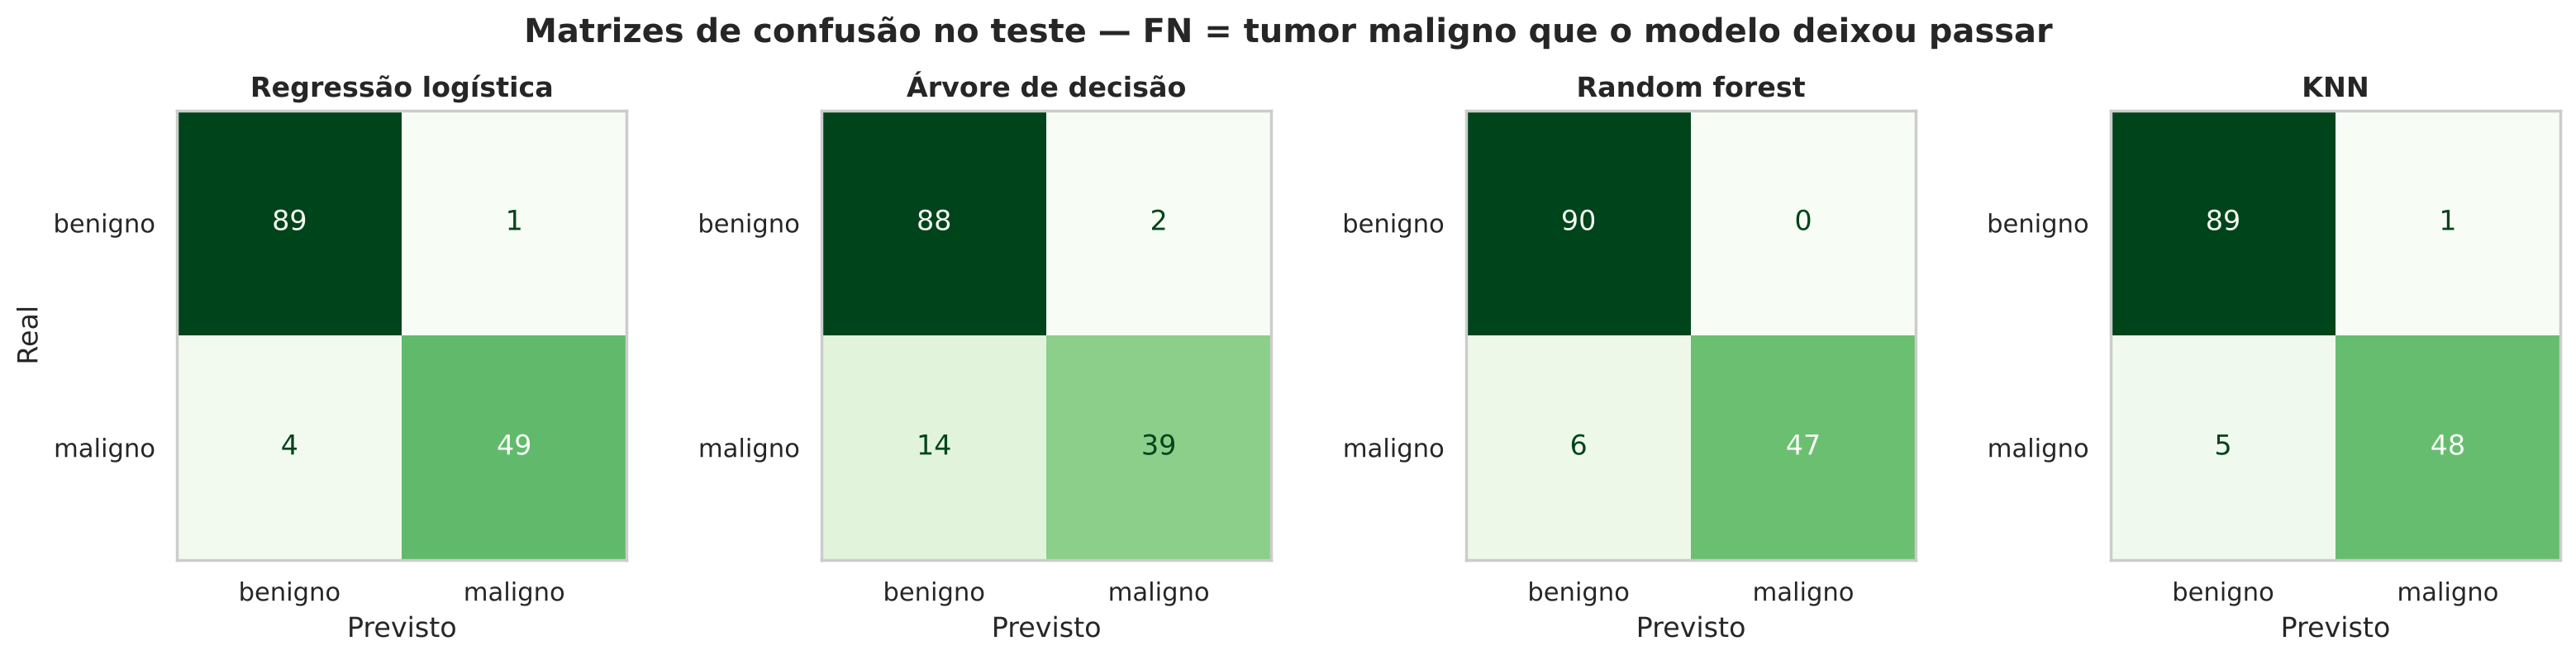

,VN,FP,FN,VP,acurácia,precisão,recall,F1,ROC-AUC
modelo,,,,,,,,,
Regressão logística,89,1,4,49,0.965,0.980,0.925,0.951,0.996
Árvore de decisão,88,2,14,39,0.888,0.951,0.736,0.830,0.969
Random forest,90,0,6,47,0.958,1.000,0.887,0.940,0.996
KNN,89,1,5,48,0.958,0.980,0.906,0.941,0.986


In [18]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score, f1_score,
                             roc_auc_score, roc_curve, classification_report)

finais = {nome: modelos[nome] for nome in CORES}
for m in finais.values():
    m.fit(X_treino, y_treino)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
linhas = []
for ax, (nome, m) in zip(axes, finais.items()):
    pred = m.predict(X_teste); proba = m.predict_proba(X_teste)[:, 1]
    ConfusionMatrixDisplay.from_predictions(y_teste, pred, display_labels=["benigno", "maligno"],
                                            cmap="Greens", colorbar=False, ax=ax)
    ax.set(title=nome, xlabel="Previsto", ylabel="Real" if ax is axes[0] else ""); ax.grid(False)
    vn, fp, fn, vp = confusion_matrix(y_teste, pred).ravel()
    linhas.append({"modelo": nome, "VN": vn, "FP": fp, "FN": fn, "VP": vp,
                   "acurácia": accuracy_score(y_teste, pred), "precisão": precision_score(y_teste, pred),
                   "recall": recall_score(y_teste, pred), "F1": f1_score(y_teste, pred),
                   "ROC-AUC": roc_auc_score(y_teste, proba)})
fig.suptitle("Matrizes de confusão no teste — FN = tumor maligno que o modelo deixou passar", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "10_matrizes_confusao.png", dpi=150, bbox_inches="tight"); plt.show()
tab_teste = pd.DataFrame(linhas).set_index("modelo")
tab_teste.round(3)

**Leitura:** quase não há falsos positivos (no máximo 2 benignos classificados como malignos); a diferença entre os modelos está nos **falsos negativos** — malignos não detectados:
* **Regressão logística:** 4 FN (recall 0,925) — o melhor resultado.
* **Random forest** e **KNN:** 5–6 FN (recall ≈ 0,89–0,91).
* **Árvore de decisão:** 14 FN (recall 0,736) — no teste, a árvore isolada deixa passar 1 em cada 4 malignos. A instabilidade apontada na validação cruzada aparece aqui com força.

Conferindo à mão (regressão logística): precisão = 49 / (49 + 1) = 0,980; recall = 49 / (49 + 4) = 0,925.

In [19]:
print("Regressão logística — relatório completo no teste")
print(classification_report(y_teste, finais["Regressão logística"].predict(X_teste),
                            target_names=["benigno", "maligno"], digits=3))

Regressão logística — relatório completo no teste
              precision    recall  f1-score   support

     benigno      0.957     0.989     0.973        90
     maligno      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143



### 5.1 Curvas ROC dos quatro modelos
A curva ROC mostra recall × taxa de falsos positivos em **todos** os limiares. Quanto mais a curva "abraça" o canto superior esquerdo, melhor; a **AUC** resume a curva num número (0,5 = chute; 1,0 = perfeito).

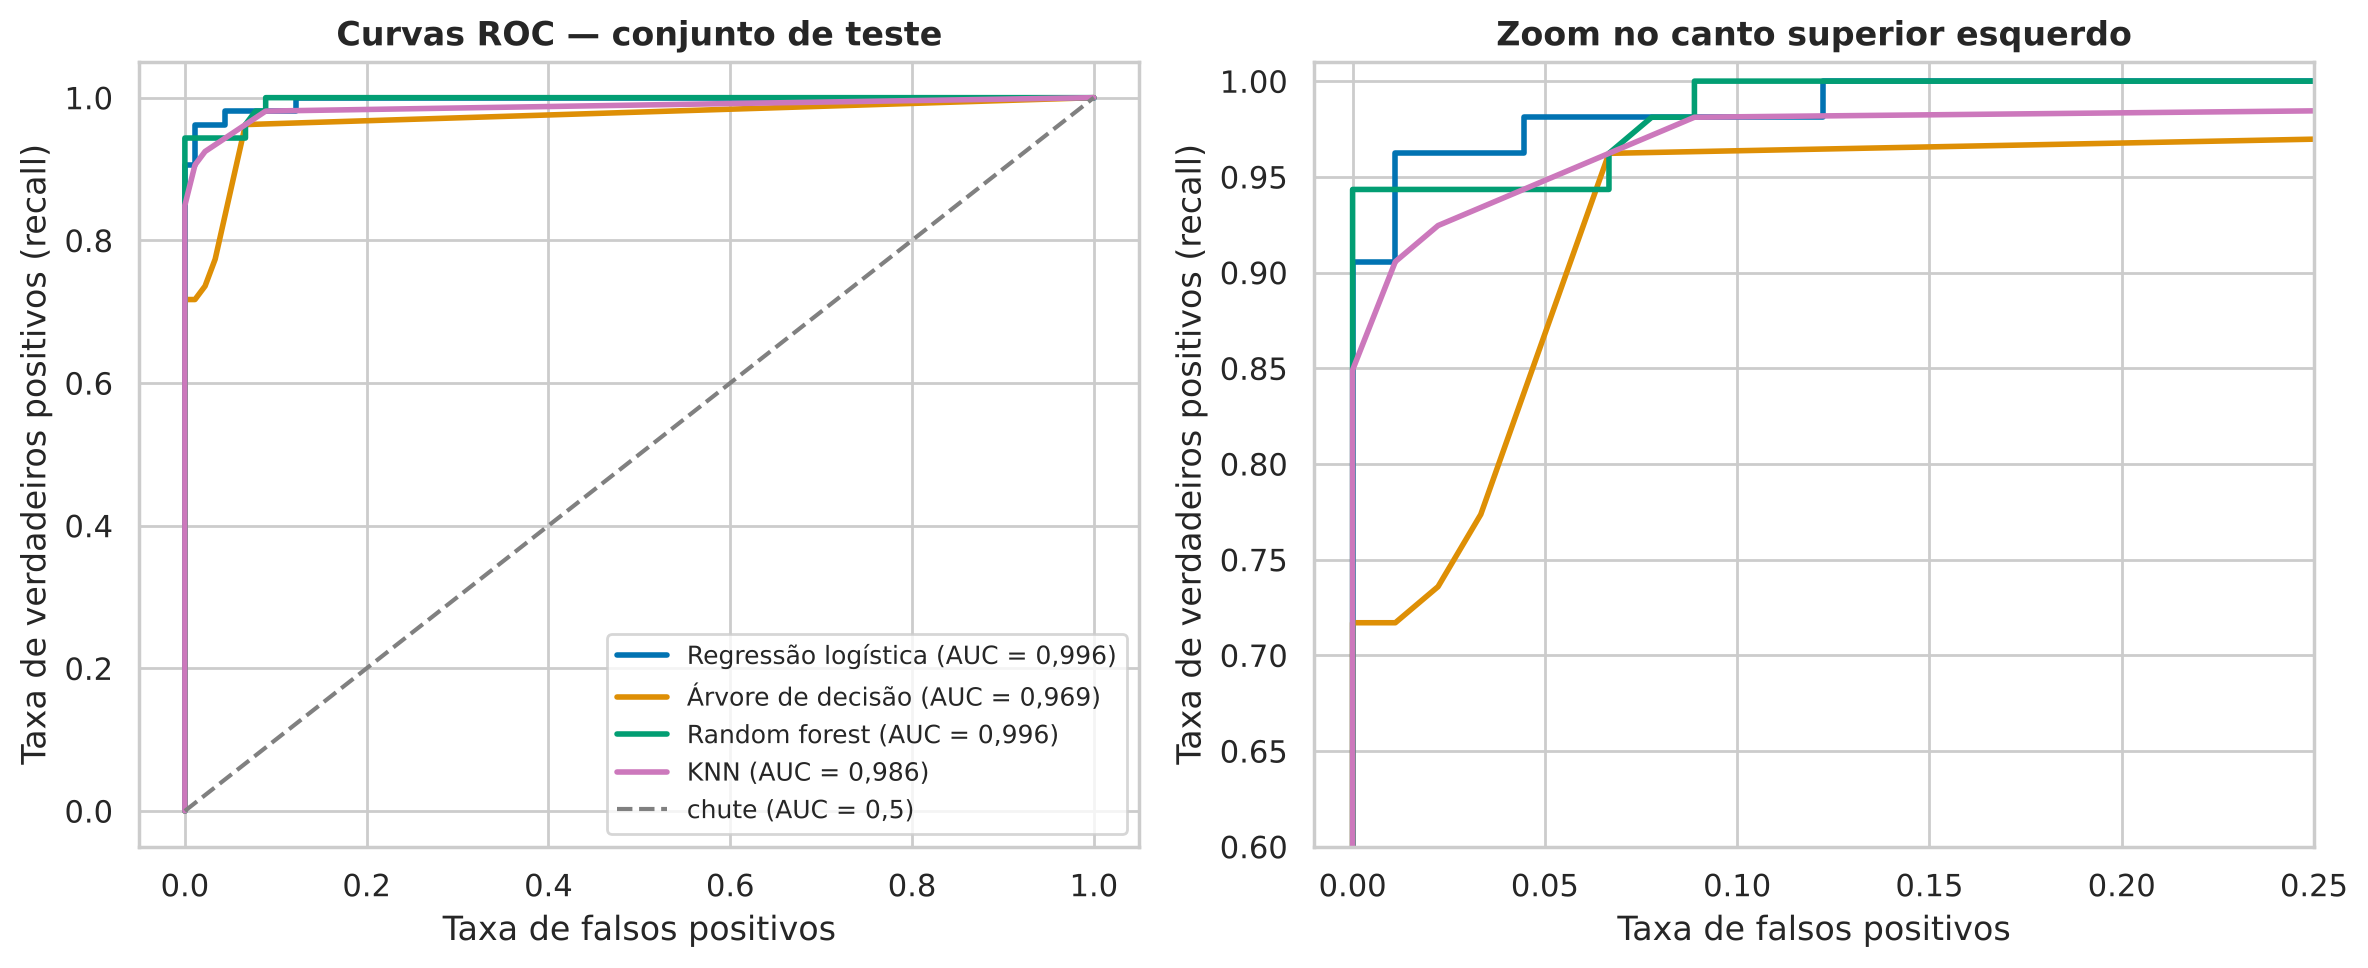

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, zoom in zip(axes, [False, True]):
    for nome, m in finais.items():
        proba = m.predict_proba(X_teste)[:, 1]
        fpr, tpr, _ = roc_curve(y_teste, proba)
        ax.plot(fpr, tpr, lw=2, color=CORES[nome],
                label=f"{nome} (AUC = {roc_auc_score(y_teste, proba):.3f})".replace(".", ","))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="chute (AUC = 0,5)")
    ax.set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)")
    if zoom:
        ax.set(xlim=(-0.01, 0.25), ylim=(0.6, 1.01), title="Zoom no canto superior esquerdo")
    else:
        ax.set(title="Curvas ROC — conjunto de teste"); ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "11_curvas_roc.png", dpi=150, bbox_inches="tight"); plt.show()

**Leitura:** regressão logística e random forest têm AUC ≈ **0,996** — ordenam quase perfeitamente o risco; KNN ≈ 0,986; a árvore ≈ 0,97, e sua curva é feita de poucos segmentos retos, porque uma árvore só produz poucas probabilidades diferentes (uma por folha). Repare: a floresta tem AUC igual à da logística, mas recall menor no limiar 0,5 — **AUC avalia a ordenação; o limiar decide os erros**.

### 5.2 O limiar: quantos malignos aceitamos perder?
Em diagnóstico, um falso negativo (maligno que passa) é muito mais grave do que um falso positivo (benigno que vai para um exame complementar). Baixar o limiar aumenta o recall:

In [21]:
proba_log = finais["Regressão logística"].predict_proba(X_teste)[:, 1]
linhas = []
for limiar in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba_log >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_teste, p).ravel()
    linhas.append({"limiar": limiar, "FN (malignos perdidos)": fn, "FP (falsos alarmes)": fp,
                   "recall": recall_score(y_teste, p), "precisão": precision_score(y_teste, p)})
pd.DataFrame(linhas).round(3).set_index("limiar")

,FN (malignos perdidos),FP (falsos alarmes),recall,precisão
limiar,,,,
0.1,1,6,0.981,0.897
0.2,2,3,0.962,0.944
0.3,2,1,0.962,0.981
0.4,3,1,0.943,0.980
0.5,4,1,0.925,0.980
0.6,5,0,0.906,1.000


**Leitura:** com a regressão logística, baixar o limiar de 0,5 para **0,3** reduz os malignos perdidos de 4 para 2, sem aumentar os falsos alarmes neste teste (continua 1); em **0,1** sobra só 1 FN, mas os falsos alarmes sobem para 6. Ou seja, recall e precisão andam em sentidos opostos. A escolha do limiar é uma decisão do especialista, que pesa o custo de cada erro — o modelo só fornece a probabilidade.

## Fechamento — quando usar cada modelo

| | Regressão logística | Árvore de decisão | Random forest | KNN |
|---|---|---|---|---|
| **Neste dataset (teste)** | melhor: acurácia 0,965, recall 0,925 | mais fraca: recall 0,736 | acurácia 0,958, AUC 0,996 | acurácia 0,958 |
| **Fronteira** | linear | degraus | degraus suavizados | irregular, local |
| **Interpretação** | coeficientes (sinal e força) | regras "se… então" — a mais fácil | importância das variáveis | exemplos vizinhos |
| **Padronizar?** | sim | não | não | **obrigatório** |
| **Ponto fraco** | relações não lineares | sobreajuste e instabilidade | mais lenta, menos explicável | lenta com muitos dados; sofre com muitas variáveis irrelevantes |
| **Use quando** | quer um baseline forte e explicável | precisa explicar regras simples | quer desempenho alto sem muito ajuste | há poucas variáveis, em escala comparável |

**Checklist do laboratório**
1. Comece pelo **baseline** e pelo **recall da classe que importa**.
2. Coloque padronização **dentro do Pipeline** (essencial para KNN e regressão logística).
3. Controle a complexidade (`max_depth`, `min_samples_leaf`, *k*) olhando treino × validação.
4. Compare os modelos com a **mesma validação cruzada**, com média e desvio-padrão.
5. Avalie o escolhido **uma vez** no teste: matriz de confusão + curva ROC.
6. Ajuste o **limiar** pelo custo dos erros.

**Exercício prático (treino, não entregue):** `Aula15_Exercicio_Pratico.ipynb` — repita o fluxo com o dataset *Pima Indians Diabetes* (também do Kaggle). **Avaliação da aula:** formulário avaliativo com 20 questões no Moodle.